# COS40007 Artificial Intelligence Engineering
## Portfolio Assessment 1 — Exploratory Data Analysis (EDA) & Data Preparation

### Selected dataset
**Dataset:** Auto MPG  
**Official source:** UCI Machine Learning Repository  
**Creator:** R. Quinlan  
**DOI:** 10.24432/C5859H  
**Official page:** https://archive.ics.uci.edu/dataset/9/auto+mpg

### Engineering context
The dataset concerns **city-cycle automobile fuel consumption**. The continuous target is fuel economy in miles per gallon (`mpg`), while the predictors describe vehicle and powertrain characteristics.

### Why this dataset fits the brief
- 398 observations: small enough to inspect, large enough for meaningful EDA.
- Continuous target (`mpg`) → regression problem.
- Six appropriate numerical predictors for Task 4.
- A real missing-data issue in `horsepower`.
- A categorical predictor (`origin`) and a text/ID field (`car_name`) that require correct data-type reasoning.
- Strong engineering relationships and genuine multicollinearity among vehicle size/power variables.

### Academic integrity
This notebook is designed as a **verifiable working analysis**. Run every cell and inspect every output before using the interpretations in your submission.

**Draft GenAI declaration — only use after you personally verify the work:**

> I used ChatGPT to assist with code comments/documentation, debugging guidance, suggesting EDA and engineering interpretation ideas, and improving code readability. All final code, interpretations, and conclusions are my own work after verification.

# 1. Imports and Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_context("notebook")

# 2. Dataset Loading

The first attempt uses the original UCI-hosted raw file. A mirror is included only as a fallback if the historical UCI path is unavailable.

The raw UCI file represents missing horsepower values using `?`, so this marker is explicitly converted to `NaN`.

In [3]:
columns = [
    "mpg",
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year",
    "origin",
    "car_name"
]

uci_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
fallback_url = "https://raw.githubusercontent.com/web-dev-champ/Auto-mpg/master/Dataset/auto-mpg.csv"

try:
    df = pd.read_csv(
        uci_url,
        sep=r"\s+",
        names=columns,
        na_values="?",
        quotechar='"'
    )
except Exception:
    df = pd.read_csv(
        fallback_url,
        na_values="?"
    )
    df.columns = [
        "mpg", "cylinders", "displacement", "horsepower",
        "weight", "acceleration", "model_year", "origin", "car_name"
    ]

# Make sure horsepower is numeric after '?' becomes NaN
df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")

print("Raw dataset shape:", df.shape)
display(df.head())

Raw dataset shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.000,8,307.000,130.000,"3,504.000",12.000,70,1,chevrolet chevelle malibu
1,15.000,8,350.000,165.000,"3,693.000",11.500,70,1,buick skylark 320
2,18.000,8,318.000,150.000,"3,436.000",11.000,70,1,plymouth satellite
3,16.000,8,304.000,150.000,"3,433.000",12.000,70,1,amc rebel sst
4,17.000,8,302.000,140.000,"3,449.000",10.500,70,1,ford torino


## Variable roles

| Variable | Role | Type used in this analysis | Engineering meaning |
|---|---|---|---|
| mpg | **Target** | Continuous | City-cycle fuel economy, miles per gallon |
| cylinders | Predictor | Numerical discrete | Number of engine cylinders |
| displacement | Predictor | Continuous | Engine displacement (cubic inches) |
| horsepower | Predictor | Continuous | Engine power |
| weight | Predictor | Continuous | Vehicle weight (lb) |
| acceleration | Predictor | Continuous | 0–60 mph time (s) |
| model_year | Predictor | Numerical discrete | Vehicle model year code |
| origin | Predictor | **Categorical** | Manufacturing origin code |
| car_name | ID/text | Categorical/string | Vehicle make/model name |

### Predictor list used for the required numerical EDA
The six predictors used to satisfy the “at least 6 numerical predictors” requirement are:

1. `cylinders`
2. `displacement`
3. `horsepower`
4. `weight`
5. `acceleration`
6. `model_year`

`origin` is coded with integers but is treated as categorical because the codes do not have a meaningful arithmetic distance.  
`car_name` is excluded from numerical correlation because it is an identifier/text label.

In [4]:
target = "mpg"

numerical_predictors = [
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year"
]

categorical_predictors = ["origin"]

print("Target:", target)
print("Numerical predictors:", numerical_predictors)
print("Categorical predictors:", categorical_predictors)

Target: mpg
Numerical predictors: ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
Categorical predictors: ['origin']


# 3. Initial Exploration — Task 1

The assignment requires:
- data loading;
- `df.shape`;
- first five rows;
- data types;
- basic statistical summary;
- initial missing-value check.

In [5]:
print("Dataset shape:")
print(df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nDataFrame info:")
df.info()

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nBasic numerical summary:")
display(df.describe().T)

print("\nInitial missing-value counts:")
display(df.isna().sum().to_frame("missing_count"))

Dataset shape:
(398, 9)

First 5 rows:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.000,8,307.000,130.000,"3,504.000",12.000,70,1,chevrolet chevelle malibu
1,15.000,8,350.000,165.000,"3,693.000",11.500,70,1,buick skylark 320
2,18.000,8,318.000,150.000,"3,436.000",11.000,70,1,plymouth satellite
3,16.000,8,304.000,150.000,"3,433.000",12.000,70,1,amc rebel sst
4,17.000,8,302.000,140.000,"3,449.000",10.500,70,1,ford torino



DataFrame info:
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    str    
dtypes: float64(5), int64(3), str(1)
memory usage: 28.1 KB

Data types:


,dtype
mpg,float64
cylinders,int64
displacement,float64
horsepower,float64
weight,float64
acceleration,float64
model_year,int64
origin,int64
car_name,str



Basic numerical summary:


,count,mean,std,min,25%,50%,75%,max
mpg,398.000,23.515,7.816,9.000,17.500,23.000,29.000,46.600
cylinders,398.000,5.455,1.701,3.000,4.000,4.000,8.000,8.000
displacement,398.000,193.426,104.270,68.000,104.250,148.500,262.000,455.000
horsepower,392.000,104.469,38.491,46.000,75.000,93.500,126.000,230.000
weight,398.000,"2,970.425",846.842,"1,613.000","2,223.750","2,803.500","3,608.000","5,140.000"
acceleration,398.000,15.568,2.758,8.000,13.825,15.500,17.175,24.800
model_year,398.000,76.010,3.698,70.000,73.000,76.000,79.000,82.000
origin,398.000,1.573,0.802,1.000,1.000,1.000,2.000,3.000



Initial missing-value counts:


,missing_count
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
car_name,0


### What to verify after running
Confirm that:
- the raw dataset contains 398 observations;
- `horsepower` is the only variable with missing values;
- `origin` and `car_name` should not be treated as continuous engineering measurements;
- the target `mpg` is continuous, so the original problem is **regression**.

# 4. Data Quality Assessment — Task 2

## 4.1 Missing values

Create a sorted table with missing count and missing percentage.

In [6]:
missing_table = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": df.isna().sum().values,
    "Missing_Percentage": df.isna().mean().values * 100
}).sort_values("Missing_Percentage", ascending=False)

display(missing_table)

,Column,Missing_Count,Missing_Percentage
3,horsepower,6,1.508
0,mpg,0,0.000
1,cylinders,0,0.000
2,displacement,0,0.000
4,weight,0,0.000
5,acceleration,0,0.000
6,model_year,0,0.000
7,origin,0,0.000
8,car_name,0,0.000


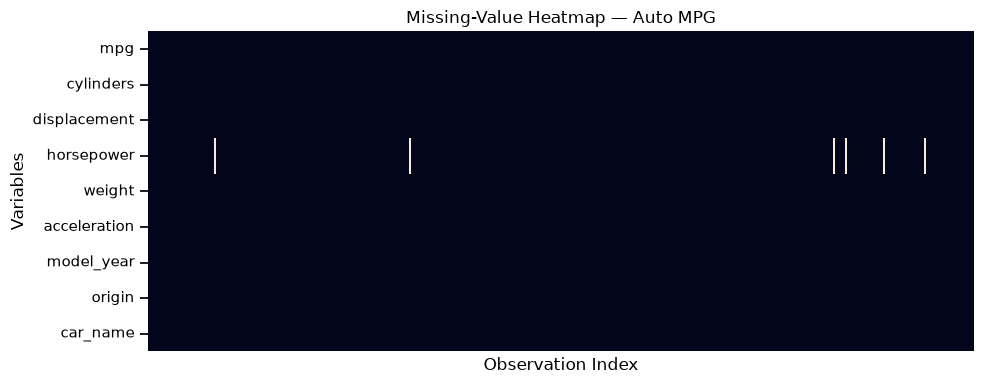

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(
    df.isna().T,
    cbar=False,
    yticklabels=True,
    xticklabels=False,
    ax=ax
)
ax.set_title("Missing-Value Heatmap — Auto MPG")
ax.set_xlabel("Observation Index")
ax.set_ylabel("Variables")
plt.tight_layout()
plt.show()

### Missing-value treatment decision

The raw dataset has only a small number of missing `horsepower` observations.  
For the main EDA, complete-case analysis is used:

- rows with missing horsepower are removed;
- no target value is missing;
- no artificial horsepower value is introduced;
- the percentage of rows removed is calculated explicitly below.

This is preferable for this portfolio because the missing fraction is small and the decision is transparent.  
A limitation is that complete-case deletion assumes the removed rows are not systematically different; this should be acknowledged.

Median imputation is a reasonable alternative for a later modelling task, but it is **not required** for this EDA.

In [8]:
rows_before = len(df)
df_clean = df.dropna(subset=["horsepower"]).copy()
rows_after = len(df_clean)

print("Rows before cleaning:", rows_before)
print("Rows after removing missing horsepower:", rows_after)
print("Rows removed:", rows_before - rows_after)
print("Percentage removed:", round(100 * (rows_before - rows_after) / rows_before, 3), "%")
print("Remaining missing values:", int(df_clean.isna().sum().sum()))

Rows before cleaning: 398
Rows after removing missing horsepower: 392
Rows removed: 6
Percentage removed: 1.508 %
Remaining missing values: 0


## 4.2 Duplicate records

In [9]:
duplicate_count = df_clean.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)

if duplicate_count > 0:
    display(df_clean[df_clean.duplicated(keep=False)].head(20))
else:
    print("No exact duplicate rows were detected.")

Exact duplicate rows: 0
No exact duplicate rows were detected.


### Duplicate handling
Do not remove records merely because two vehicles share similar engineering specifications.  
Only **exact full-row duplicates** would be candidates for duplicate removal.

## 4.3 Outliers

The brief requires boxplots for numerical features.  
Here, the six numerical predictors **and the numerical target** are checked.

IQR rule:

- IQR = Q3 − Q1
- Lower bound = Q1 − 1.5 × IQR
- Upper bound = Q3 + 1.5 × IQR

Potential outliers are not automatically removed.

In [10]:
outlier_columns = numerical_predictors + [target]

def iqr_outlier_summary(dataframe, columns):
    rows = []
    for col in columns:
        s = dataframe[col].dropna()
        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        mask = (s < lower) | (s > upper)

        rows.append({
            "Feature": col,
            "Number_of_Outliers": int(mask.sum()),
            "Percentage": 100 * mask.sum() / len(s),
            "Lower_Bound": lower,
            "Upper_Bound": upper
        })

    return pd.DataFrame(rows)

outlier_summary = iqr_outlier_summary(df_clean, outlier_columns)
display(outlier_summary)

,Feature,Number_of_Outliers,Percentage,Lower_Bound,Upper_Bound
0,cylinders,0,0.000,-2.000,14.000
1,displacement,0,0.000,-151.125,531.875
2,horsepower,10,2.551,-1.500,202.500
3,weight,0,0.000,141.000,"5,699.000"
4,acceleration,11,2.806,8.900,21.900
5,model_year,0,0.000,64.000,88.000
6,mpg,0,0.000,-1.000,47.000


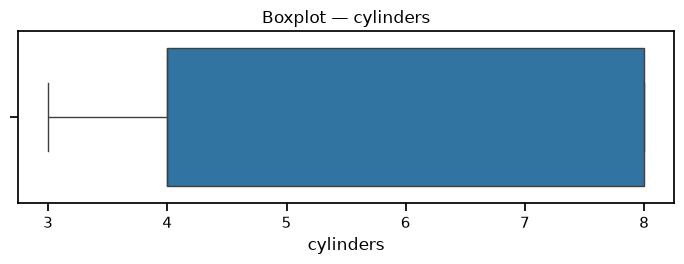

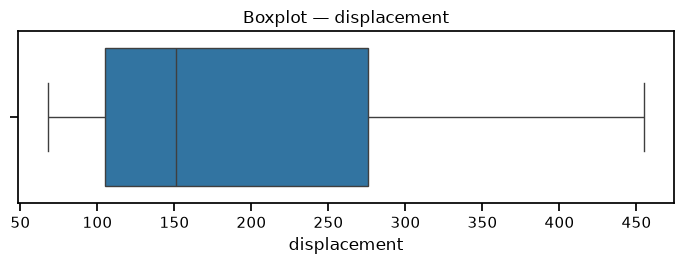

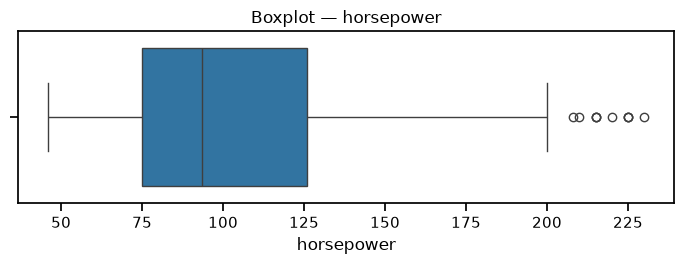

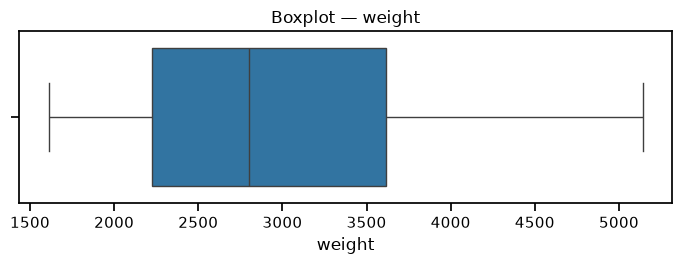

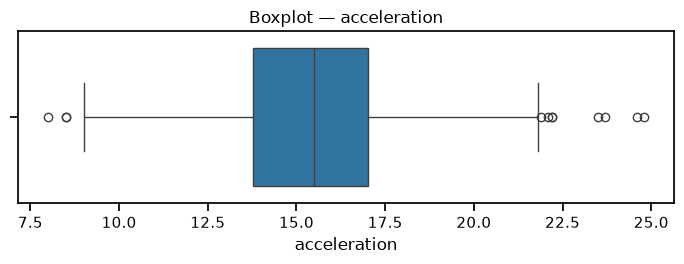

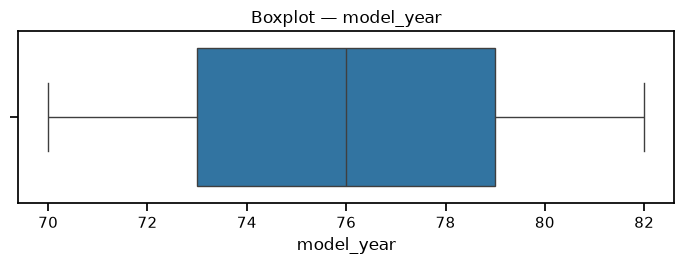

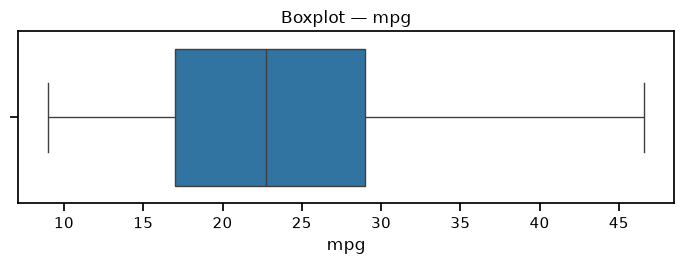

In [11]:
for col in outlier_columns:
    fig, ax = plt.subplots(figsize=(7, 2.8))
    sns.boxplot(x=df_clean[col], ax=ax)
    ax.set_title(f"Boxplot — {col}")
    ax.set_xlabel(col)
    plt.tight_layout()
    plt.show()

### Engineering interpretation of potential outliers

Possible extreme values in `horsepower`, `weight`, `displacement`, `acceleration`, or `mpg` should first be considered as potentially valid vehicle designs.

Examples:
- high horsepower may represent performance vehicles;
- high weight may represent large vehicles or wagons;
- unusually high MPG may reflect small or diesel vehicles;
- extreme acceleration time may reflect low-powered or heavy vehicles.

Therefore the default decision is **retain and investigate**, not automatic deletion.

## 4.4 Data types after cleaning

In [12]:
display(df_clean.dtypes.to_frame("cleaned_dtype"))

,cleaned_dtype
mpg,float64
cylinders,int64
displacement,float64
horsepower,float64
weight,float64
acceleration,float64
model_year,int64
origin,int64
car_name,str


# 5. Target Variable Preparation — Task 3

## 5.1 Target identification

**Target:** `mpg`  
**Type:** continuous numerical  
**Original problem type:** regression

The assignment asks a numerical target to be converted into 3–5 meaningful classes.

Three methods are considered:

1. **Equal-width:** simple but may generate uneven class sizes.
2. **Equal-frequency / quantile:** produces approximately balanced groups.
3. **Engineering thresholds:** should only be used when a defensible fuel-economy standard or project requirement is specified.

For this assignment, four quantile-based classes are recommended because the brief explicitly asks for reasonably balanced classes and no project-specific engineering thresholds were supplied.

MPG target summary:


,count,mean,std,min,25%,50%,75%,max
mpg,392.000,23.446,7.805,9.000,17.000,22.750,29.000,46.600


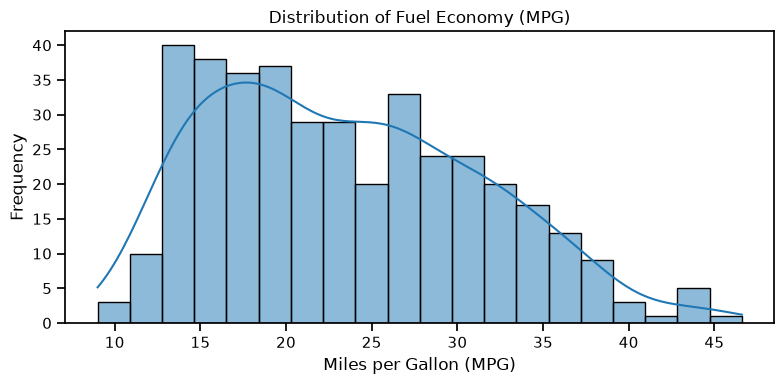

In [13]:
print("MPG target summary:")
display(df_clean[target].describe().to_frame().T)

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df_clean[target], bins=20, kde=True, ax=ax)
ax.set_title("Distribution of Fuel Economy (MPG)")
ax.set_xlabel("Miles per Gallon (MPG)")
ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

In [14]:
class_labels = ["Low", "Moderate", "High", "Very High"]

# Equal-width
df_clean["MPG_Class_EqualWidth"] = pd.cut(
    df_clean[target],
    bins=4,
    labels=class_labels,
    include_lowest=True
)

# Equal-frequency / quantile
df_clean["MPG_Class_Quantile"], quantile_edges = pd.qcut(
    df_clean[target],
    q=4,
    labels=class_labels,
    retbins=True,
    duplicates="drop"
)

comparison = pd.DataFrame({
    "Equal_Width_Count": df_clean["MPG_Class_EqualWidth"].value_counts().sort_index(),
    "Quantile_Count": df_clean["MPG_Class_Quantile"].value_counts().sort_index()
})

comparison["Equal_Width_Percentage"] = (
    comparison["Equal_Width_Count"] / len(df_clean) * 100
)
comparison["Quantile_Percentage"] = (
    comparison["Quantile_Count"] / len(df_clean) * 100
)

display(comparison)

boundary_table = pd.DataFrame({
    "Boundary": ["Minimum/Q0", "Q25", "Q50", "Q75", "Maximum/Q100"],
    "MPG": quantile_edges
})
display(boundary_table)

,Equal_Width_Count,Quantile_Count,Equal_Width_Percentage,Quantile_Percentage
Low,127,99,32.398,25.255
Moderate,148,97,37.755,24.745
High,99,101,25.255,25.765
Very High,18,95,4.592,24.235


,Boundary,MPG
0,Minimum/Q0,9.000
1,Q25,17.000
2,Q50,22.750
3,Q75,29.000
4,Maximum/Q100,46.600


,Count,Percentage
MPG_Class,,
Low,99,25.255
Moderate,97,24.745
High,101,25.765
Very High,95,24.235


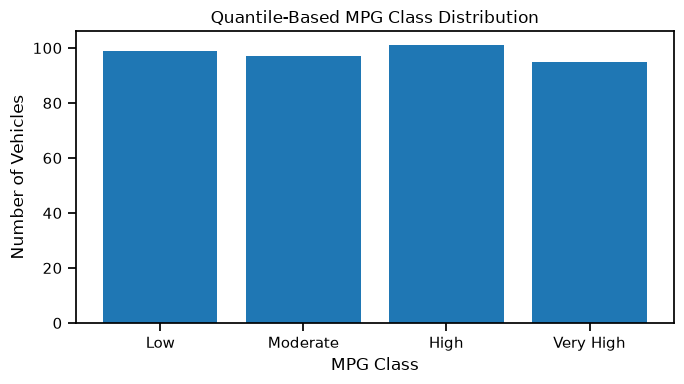

Largest class percentage: 25.765306122448976
Severe imbalance (>80%): False


In [15]:
df_clean["MPG_Class"] = df_clean["MPG_Class_Quantile"]

class_counts = df_clean["MPG_Class"].value_counts().sort_index()
class_percentages = class_counts / len(df_clean) * 100

class_table = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})
display(class_table)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(class_counts.index.astype(str), class_counts.values)
ax.set_title("Quantile-Based MPG Class Distribution")
ax.set_xlabel("MPG Class")
ax.set_ylabel("Number of Vehicles")
plt.tight_layout()
plt.show()

print("Largest class percentage:", class_percentages.max())
print("Severe imbalance (>80%):", bool(class_percentages.max() > 80))

### Target-class interpretation
The class labels are analytical groupings for this assignment.  
They are **not regulatory fuel-economy grades**.

# 6. Univariate Analysis — Task 4

All six required numerical predictors are analysed.

The summary table includes:
- mean;
- median;
- standard deviation;
- minimum;
- maximum;
- quartiles;
- skewness.

In [16]:
summary_stats = pd.DataFrame({
    "Mean": df_clean[numerical_predictors].mean(),
    "Median": df_clean[numerical_predictors].median(),
    "Std_Dev": df_clean[numerical_predictors].std(),
    "Minimum": df_clean[numerical_predictors].min(),
    "Q1": df_clean[numerical_predictors].quantile(0.25),
    "Q3": df_clean[numerical_predictors].quantile(0.75),
    "Maximum": df_clean[numerical_predictors].max(),
    "Skewness": df_clean[numerical_predictors].skew()
})

display(summary_stats)

,Mean,Median,Std_Dev,Minimum,Q1,Q3,Maximum,Skewness
cylinders,5.472,4.000,1.706,3.000,4.000,8.000,8.000,0.508
displacement,194.412,151.000,104.644,68.000,105.000,275.750,455.000,0.702
horsepower,104.469,93.500,38.491,46.000,75.000,126.000,230.000,1.087
weight,"2,977.584","2,803.500",849.403,"1,613.000","2,225.250","3,614.750","5,140.000",0.520
acceleration,15.541,15.500,2.759,8.000,13.775,17.025,24.800,0.292
model_year,75.980,76.000,3.684,70.000,73.000,79.000,82.000,0.020


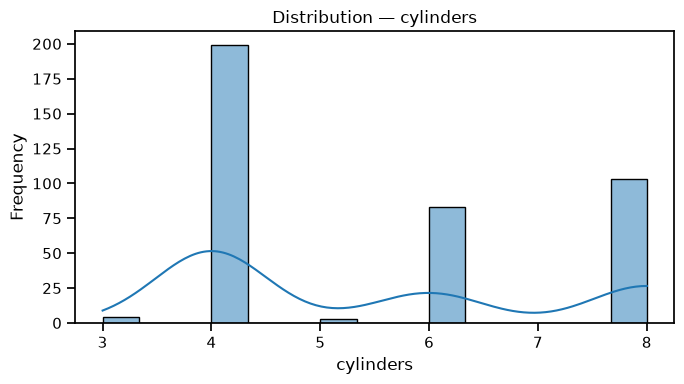

cylinders: skewness = 0.508; moderately positively skewed.


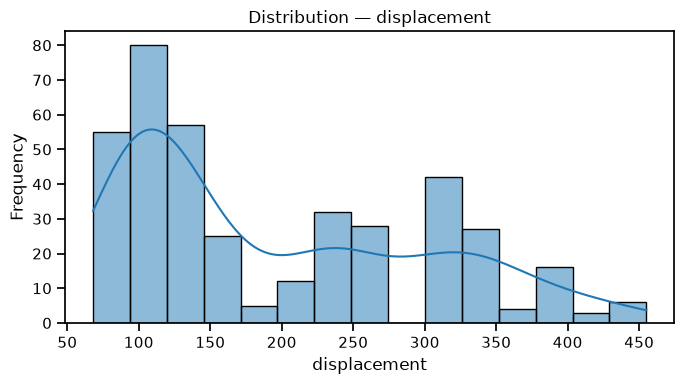

displacement: skewness = 0.702; moderately positively skewed.


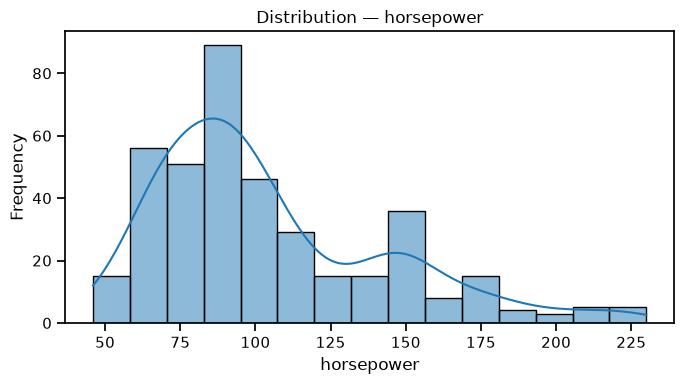

horsepower: skewness = 1.087; strongly positively skewed.


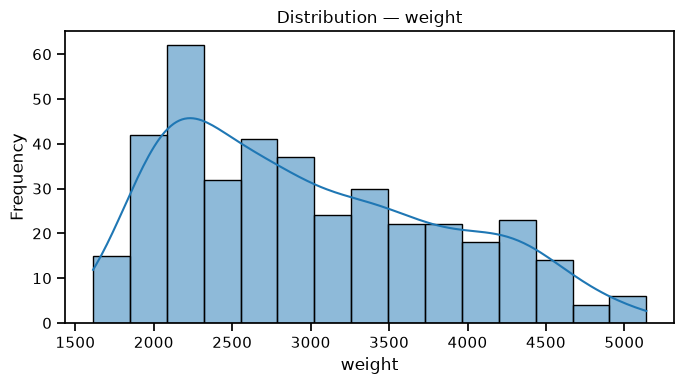

weight: skewness = 0.520; moderately positively skewed.


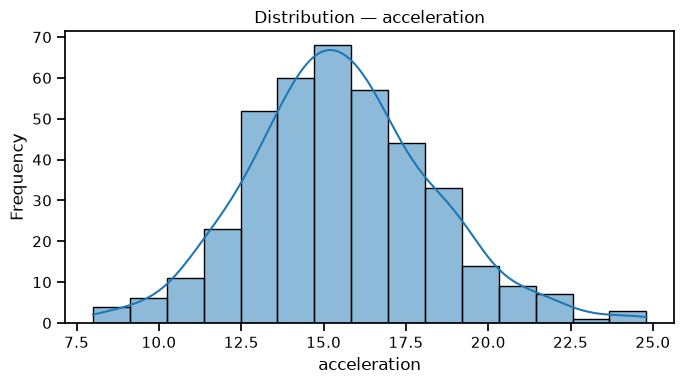

acceleration: skewness = 0.292; approximately symmetric / mildly skewed.


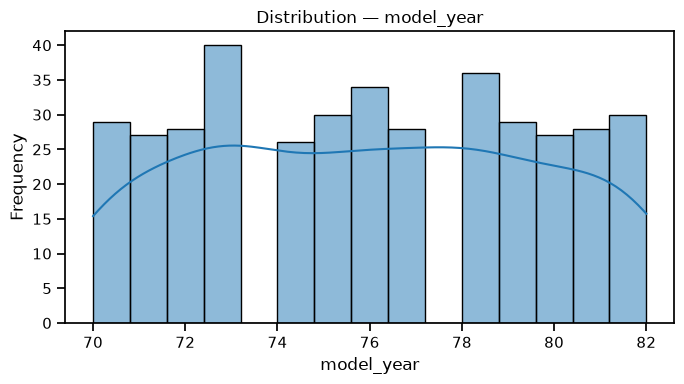

model_year: skewness = 0.020; approximately symmetric / mildly skewed.


In [17]:
def skew_label(value):
    if value >= 1:
        return "strongly positively skewed"
    if value >= 0.5:
        return "moderately positively skewed"
    if value > -0.5:
        return "approximately symmetric / mildly skewed"
    if value > -1:
        return "moderately negatively skewed"
    return "strongly negatively skewed"

for col in numerical_predictors:
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.histplot(df_clean[col], bins=15, kde=True, ax=ax)
    ax.set_title(f"Distribution — {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
    plt.tight_layout()
    plt.show()

    skew = df_clean[col].skew()
    print(
        f"{col}: skewness = {skew:.3f}; "
        f"{skew_label(skew)}."
    )

### What to interpret after each plot

- **Cylinders:** discrete clusters represent common engine configurations rather than a smooth continuous distribution.
- **Displacement:** larger engine sizes may create positive skew.
- **Horsepower:** high-performance vehicles may form the upper tail.
- **Weight:** reflects different vehicle sizes and body types.
- **Acceleration:** measured as 0–60 mph time, so a larger value means **slower** acceleration.
- **Model year:** a roughly spread distribution indicates coverage across the 1970–1982 period.

Do not call a distribution “normal” or “skewed” unless the executed figure/statistics support it.

# 7. Multivariate Analysis — Task 5

## 7.1 Correlation matrix and heatmap

`origin` and `car_name` are excluded from the main Pearson matrix because the core requirement is to analyse numerical engineering predictors.  
`origin` is a category code, not a continuous measurement.

,cylinders,displacement,horsepower,weight,acceleration,model_year,mpg
cylinders,1.000,0.951,0.843,0.898,-0.505,-0.346,-0.778
displacement,0.951,1.000,0.897,0.933,-0.544,-0.370,-0.805
horsepower,0.843,0.897,1.000,0.865,-0.689,-0.416,-0.778
weight,0.898,0.933,0.865,1.000,-0.417,-0.309,-0.832
acceleration,-0.505,-0.544,-0.689,-0.417,1.000,0.290,0.423
model_year,-0.346,-0.370,-0.416,-0.309,0.290,1.000,0.581
mpg,-0.778,-0.805,-0.778,-0.832,0.423,0.581,1.000


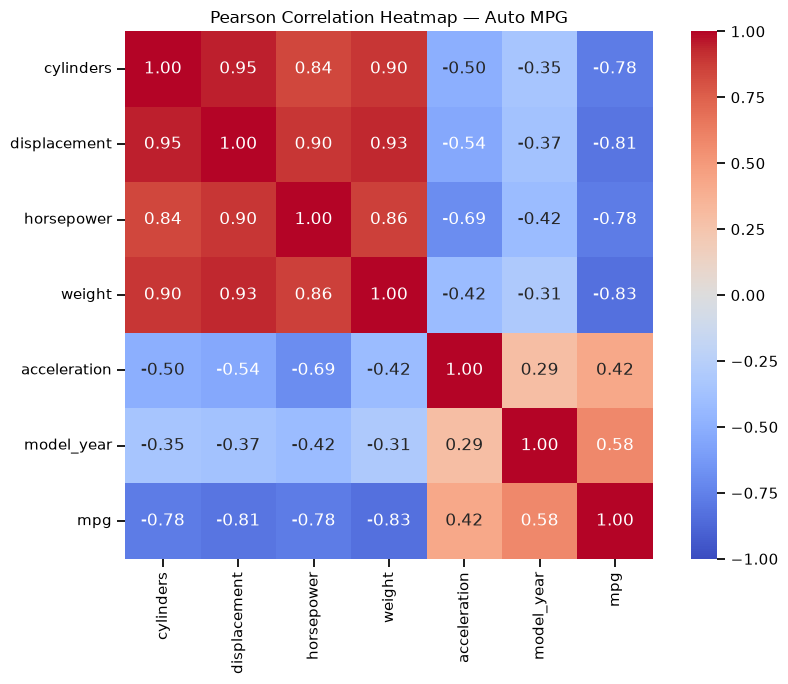

In [18]:
corr_cols = numerical_predictors + [target]
corr = df_clean[corr_cols].corr(method="pearson")

display(corr.round(3))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax
)
ax.set_title("Pearson Correlation Heatmap — Auto MPG")
plt.tight_layout()
plt.show()

## 7.2 Top three features correlated with the target

Ranking uses absolute correlation magnitude, while the signed coefficient is preserved.

In [19]:
target_corr = corr[target].drop(target)

top3 = (
    target_corr
    .reindex(target_corr.abs().sort_values(ascending=False).index)
    .head(3)
)

top3_table = pd.DataFrame({
    "Rank": range(1, 4),
    "Feature": top3.index,
    "Correlation_with_Target": top3.values,
    "Direction": ["Positive" if x > 0 else "Negative" for x in top3.values]
})

display(top3_table)

,Rank,Feature,Correlation_with_Target,Direction
0,1,weight,-0.832,Negative
1,2,displacement,-0.805,Negative
2,3,horsepower,-0.778,Negative


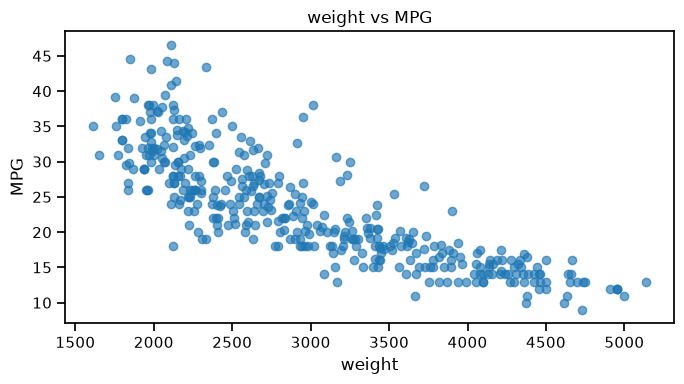

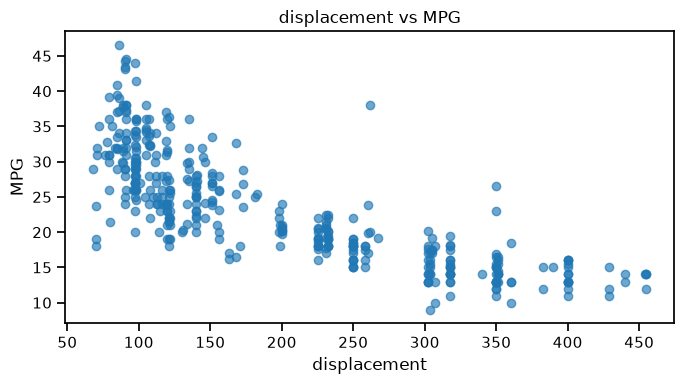

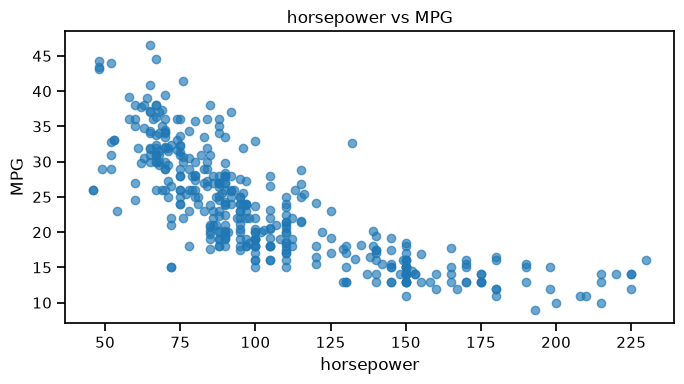

In [20]:
for feature in top3.index:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.scatter(df_clean[feature], df_clean[target], alpha=0.65)
    ax.set_title(f"{feature} vs MPG")
    ax.set_xlabel(feature)
    ax.set_ylabel("MPG")
    plt.tight_layout()
    plt.show()

## 7.3 Multicollinearity

Predictor pairs with |r| ≥ 0.70 are flagged.

In [21]:
threshold = 0.70
predictor_corr = corr.loc[numerical_predictors, numerical_predictors]

pairs = []
for i in range(len(numerical_predictors)):
    for j in range(i + 1, len(numerical_predictors)):
        r = predictor_corr.iloc[i, j]
        if abs(r) >= threshold:
            pairs.append({
                "Feature_1": numerical_predictors[i],
                "Feature_2": numerical_predictors[j],
                "Correlation": r,
                "Abs_Correlation": abs(r)
            })

multicollinearity_table = pd.DataFrame(pairs)

if multicollinearity_table.empty:
    print("No predictor pairs have |r| >= 0.70.")
else:
    display(
        multicollinearity_table.sort_values(
            "Abs_Correlation",
            ascending=False
        )
    )

,Feature_1,Feature_2,Correlation,Abs_Correlation
0,cylinders,displacement,0.951,0.951
4,displacement,weight,0.933,0.933
2,cylinders,weight,0.898,0.898
3,displacement,horsepower,0.897,0.897
5,horsepower,weight,0.865,0.865
1,cylinders,horsepower,0.843,0.843


## 7.4 Predictor relationships / pairplot

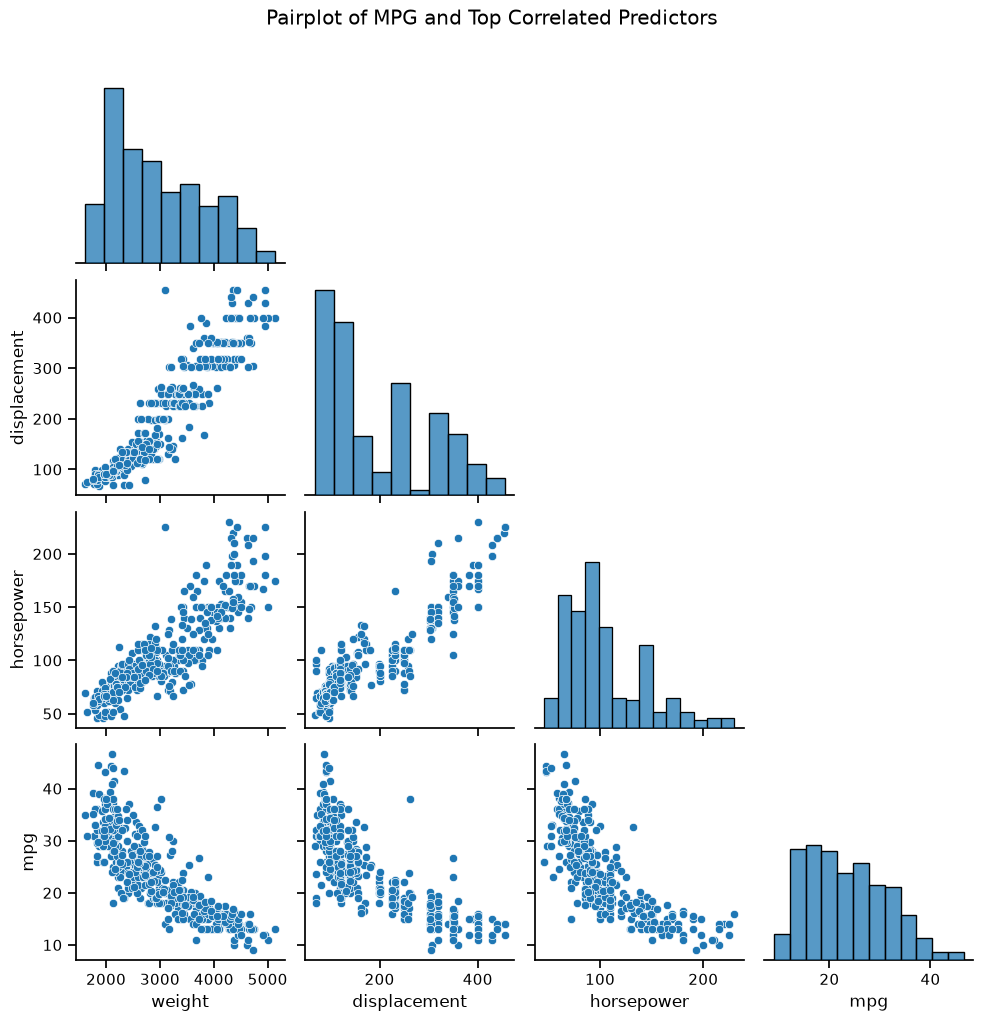

In [22]:
key_features = list(top3.index) + [target]

g = sns.pairplot(
    df_clean[key_features],
    corner=True,
    diag_kind="hist"
)
g.fig.suptitle("Pairplot of MPG and Top Correlated Predictors", y=1.02)
plt.show()

### Multivariate interpretation checklist

Look for:
- negative trends between MPG and vehicle size/power;
- nonlinear relationships;
- clusters caused by common engine configurations;
- unusual vehicles;
- overlapping information among cylinders, displacement, horsepower and weight;
- whether scatter increases/decreases across the predictor range.

Correlation does not prove causation.

# 8. Initial Insights for Modelling — Discussion Only

The brief asks for **discussion, not model training**.

### Promising features
The executed top-three correlation table should be used as the primary statistical evidence.  
Weight, engine displacement, horsepower and cylinder count should also be interpreted as a related engineering group rather than independent physical effects.

### Possible preprocessing
- Missing horsepower: complete-case deletion is used in this EDA; median imputation could be tested later.
- Scaling: recommended before KNN/SVM because predictors have very different units/ranges.
- Encoding: `origin` should be one-hot encoded if used in a later model.
- `car_name`: should normally be excluded or engineered carefully rather than encoded as a simple number.
- Outliers: retain unless engineering evidence shows error.
- Feature selection: important because the mechanical size/power variables are strongly correlated.
- Nonlinear transformations/interactions: may be useful if scatterplots show curvature.

### Suitable future regression models
- Linear Regression — interpretable baseline;
- Ridge/Lasso — useful under multicollinearity;
- Decision Tree Regression — nonlinear splits;
- Random Forest Regression — nonlinear interactions;
- Gradient Boosting — strong nonlinear prediction;
- SVR — possible after scaling.

**Do not train these models in this assessment.**

# 9. Engineering Interpretation — Task 6

The main relationships have clear automotive-engineering meaning:

- A heavier vehicle requires more energy to accelerate and maintain motion, so lower MPG is physically plausible.
- Larger displacement and higher horsepower often occur in larger/more powerful engines and may be associated with higher fuel consumption.
- Cylinders, displacement, horsepower and weight are strongly related design characteristics. Their strong mutual correlations can create multicollinearity, so it would be incorrect to interpret every correlation as an independent causal effect.
- `model_year` captures technological and regulatory change over 1970–1982. Any MPG relationship with year may reflect improvements in vehicle design, powertrain efficiency, market composition and regulation rather than a single physical mechanism.
- Acceleration is recorded as time to reach 60 mph; larger values mean slower acceleration, which must be remembered when interpreting correlation direction.

### Important variables not present
Potentially useful omitted variables include:
- transmission type and gear ratios;
- aerodynamic drag / frontal area;
- rolling resistance;
- fuel type in a structured variable;
- detailed engine technology;
- vehicle body style;
- test temperature and detailed test-cycle conditions.

If a statistical relationship cannot be confirmed from the available variables alone:

> “Further domain information would be required to confirm this interpretation.”

# 10. Challenges Encountered — Task 7

Only retain challenges confirmed by the executed notebook.

Expected genuine issues include:
1. `horsepower` contains missing values represented as `?` in the raw source.
2. Removing those observations reduces the dataset slightly and may introduce bias if missingness is systematic.
3. Several mechanical predictors are strongly correlated.
4. Some numerical distributions are discrete or skewed.
5. IQR flags may identify valid performance/extreme vehicle designs rather than data errors.
6. `origin` is stored numerically but should be treated as categorical.
7. `car_name` is text/ID and is unsuitable for ordinary Pearson correlation.

# 11. Responsible AI Reflection — Task 8

## Q1. How might poor data quality affect model reliability?

If the `?` horsepower entries were left as strings, horsepower could have the wrong data type and be omitted or mishandled in statistical calculations. Removing or imputing missing values without justification could bias results. Likewise, automatically deleting high-horsepower or high-MPG vehicles because they are statistical outliers could remove valid engineering cases. Poor handling of these issues could distort correlations and make a later fuel-economy model less reliable.

## Q2. What ethical or bias issues might exist?

The main concern is representativeness. The dataset covers vehicles from approximately the 1970–1982 period and therefore does not represent modern engine technologies, hybrid/electric powertrains, current vehicle mass, aerodynamics or present-day regulations. A model built from this dataset should not be presented as a reliable predictor for modern vehicles without external validation. The `origin` variable can also reflect historical market composition and technology differences; it should not be interpreted as an inherent causal property of a country or region.

# 12. Next Steps — Task 9

If more time were available:

1. investigate the six missing-horsepower vehicles to assess whether missingness is systematic;
2. compare complete-case analysis with median or model-based imputation;
3. analyse `origin` as a categorical variable;
4. engineer power-to-weight or displacement-to-weight features;
5. investigate nonlinear relationships;
6. compare results with and without IQR-flagged observations;
7. obtain additional vehicle-design features;
8. in a later modelling task, compare regression algorithms using cross-validation;
9. validate any model on newer or independent automotive data.

# 13. Verified Reference Values for Cross-Checking

These values are included only as **cross-check targets** after you run the notebook.  
They should not replace your executed output.

For the conventional complete-case version with 392 vehicles:
- mean MPG ≈ 23.446;
- MPG quartiles ≈ 17.0, 22.75, 29.0;
- mean horsepower ≈ 104.469;
- mean weight ≈ 2977.584 lb;
- strongest MPG correlations are expected to include weight, displacement and horsepower;
- strong multicollinearity is expected among cylinders, displacement, horsepower and weight.

If your executed results differ materially, stop and inspect the loading/cleaning steps.

# 14. Report Facts Cell

In [23]:
print("=== DATASET OVERVIEW ===")
print("Raw shape:", df.shape)
print("Clean shape:", df_clean.shape)
print("Target:", target)
print("Original problem type: Regression")

print("\n=== MISSING VALUES ===")
display(missing_table)

print("\n=== DUPLICATES ===")
print("Exact duplicate rows:", duplicate_count)

print("\n=== OUTLIERS ===")
display(outlier_summary)

print("\n=== TARGET CLASS BOUNDARIES ===")
display(boundary_table)

print("\n=== TARGET CLASS DISTRIBUTION ===")
display(class_table)

print("\n=== UNIVARIATE SUMMARY ===")
display(summary_stats)

print("\n=== TOP 3 TARGET CORRELATIONS ===")
display(top3_table)

print("\n=== MULTICOLLINEARITY ===")
if multicollinearity_table.empty:
    print("No pairs >= |0.70|")
else:
    display(multicollinearity_table.sort_values("Abs_Correlation", ascending=False))

=== DATASET OVERVIEW ===
Raw shape: (398, 9)
Clean shape: (392, 12)
Target: mpg
Original problem type: Regression

=== MISSING VALUES ===


,Column,Missing_Count,Missing_Percentage
3,horsepower,6,1.508
0,mpg,0,0.000
1,cylinders,0,0.000
2,displacement,0,0.000
4,weight,0,0.000
5,acceleration,0,0.000
6,model_year,0,0.000
7,origin,0,0.000
8,car_name,0,0.000



=== DUPLICATES ===
Exact duplicate rows: 0

=== OUTLIERS ===


,Feature,Number_of_Outliers,Percentage,Lower_Bound,Upper_Bound
0,cylinders,0,0.000,-2.000,14.000
1,displacement,0,0.000,-151.125,531.875
2,horsepower,10,2.551,-1.500,202.500
3,weight,0,0.000,141.000,"5,699.000"
4,acceleration,11,2.806,8.900,21.900
5,model_year,0,0.000,64.000,88.000
6,mpg,0,0.000,-1.000,47.000



=== TARGET CLASS BOUNDARIES ===


...

,Mean,Median,Std_Dev,Minimum,Q1,Q3,Maximum,Skewness
cylinders,5.472,4.000,1.706,3.000,4.000,8.000,8.000,0.508
displacement,194.412,151.000,104.644,68.000,105.000,275.750,455.000,0.702
horsepower,104.469,93.500,38.491,46.000,75.000,126.000,230.000,1.087
weight,"2,977.584","2,803.500",849.403,"1,613.000","2,225.250","3,614.750","5,140.000",0.520
acceleration,15.541,15.500,2.759,8.000,13.775,17.025,24.800,0.292
model_year,75.980,76.000,3.684,70.000,73.000,79.000,82.000,0.020



=== TOP 3 TARGET CORRELATIONS ===


,Rank,Feature,Correlation_with_Target,Direction
0,1,weight,-0.832,Negative
1,2,displacement,-0.805,Negative
2,3,horsepower,-0.778,Negative



=== MULTICOLLINEARITY ===


,Feature_1,Feature_2,Correlation,Abs_Correlation
0,cylinders,displacement,0.951,0.951
4,displacement,weight,0.933,0.933
2,cylinders,weight,0.898,0.898
3,displacement,horsepower,0.897,0.897
5,horsepower,weight,0.865,0.865
1,cylinders,horsepower,0.843,0.843


# 15. Final Compliance Checklist

| Assessment requirement | Completed? | Evidence |
|---|---|---|
| Dataset loading | Yes | Section 2 |
| `df.shape` | Yes | Section 3 |
| `df.head()` | Yes | Sections 2–3 |
| `df.info()` | Yes | Section 3 |
| `df.dtypes` | Yes | Section 3 |
| `df.describe()` | Yes | Section 3 |
| Initial missing check | Yes | Section 3 |
| Missing table with percentage | Yes | Section 4.1 |
| Missing heatmap | Yes | Section 4.1 |
| Missing treatment justified | Yes | Section 4.1 |
| Duplicate count/examples | Yes | Section 4.2 |
| Boxplots for numerical features | Yes | Section 4.3 |
| IQR outlier table | Yes | Section 4.3 |
| Outlier treatment discussion | Yes | Section 4.3 |
| Data types after cleaning | Yes | Section 4.4 |
| Target name/type | Yes | Section 5 |
| Regression/classification determination | Yes | Section 5 |
| 3–5 target classes | Yes — 4 | Section 5 |
| Compare binning approaches | Yes | Section 5 |
| Explain selected boundaries | Yes | Section 5 |
| Class counts/percentages | Yes | Section 5 |
| Class distribution plot | Yes | Section 5 |
| Imbalance check | Yes | Section 5 |
| List all predictors | Yes | Section 2 |
| ≥6 numerical predictor distributions | Yes — exactly 6 | Section 6 |
| Mean/median/std/min/max/quartiles/skewness | Yes | Section 6 |
| Distribution interpretation guidance | Yes | Section 6 |
| Pearson correlation matrix | Yes | Section 7 |
| Correlation heatmap | Yes | Section 7 |
| Top 3 correlations with sign | Yes | Section 7.2 |
| Multicollinearity at |r| ≥ 0.7 | Yes | Section 7.3 |
| Scatterplots/pairplot | Yes | Sections 7.2–7.4 |
| Linear/nonlinear/clustering discussion | Yes | Section 7 |
| Initial modelling insights only | Yes | Section 8 |
| Engineering interpretation | Yes | Section 9 |
| Challenges encountered | Yes | Section 10 |
| Responsible AI reflection | Yes | Section 11 |
| Next steps | Yes | Section 12 |
| GenAI declaration draft | Yes | Opening |
| Student verification | **Still required** | Run and inspect notebook |